In [15]:
import pandas as pd 
import numpy as np
from sklearn.datasets import make_regression 

In [2]:
x, y = make_regression(n_samples=4, n_features=1, n_informative=1, n_targets=1, noise=80, random_state=13)

In [3]:
print(x.shape)
print(y.shape)

(4, 1)
(4,)


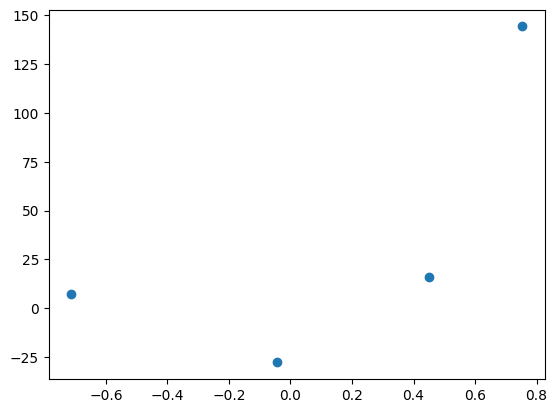

In [5]:
import matplotlib.pyplot as plt

plt.scatter(x, y)

In [6]:
# Frist applied OLS(ordinary least square) so that we know m
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [7]:
lr.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [8]:
lr.coef_

array([78.35063668])

In [9]:
lr.intercept_

np.float64(26.15963284313262)

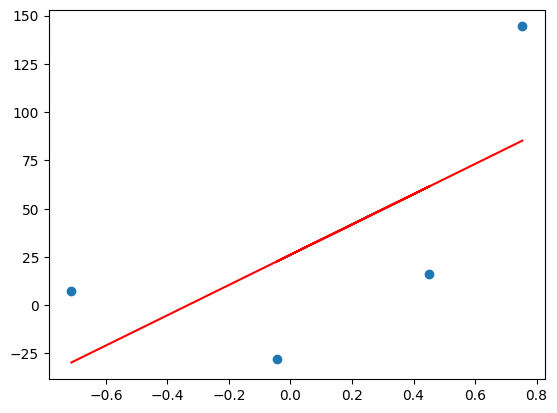

In [11]:
plt.scatter(x,y)
plt.plot(x,lr.predict(x), color = 'red')

In [12]:
# Lets apply gradient descent assuming slope is constant m = 78.35
# Let's assume starting value for intercept b = 0
y_pred = ((78.35*x)+0).reshape(4)

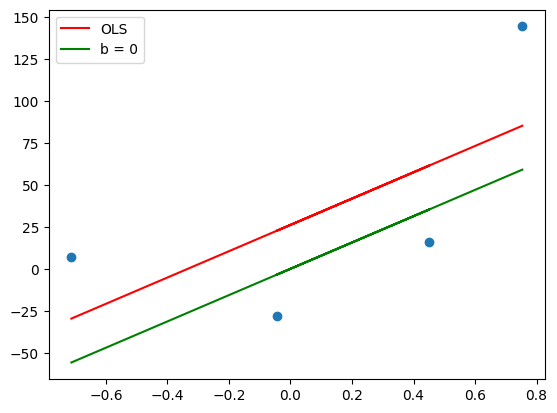

In [14]:
plt.scatter(x,y)
plt.plot(x, lr.predict(x), color='red', label='OLS')
plt.plot(x, y_pred, color='green', label='b = 0')
plt.legend()
plt.show()

In [16]:
m = 78.35
b = 0

loss_slope = -2* np.sum(y - m*x.ravel()-b)

In [17]:
print(loss_slope)

-209.27763408209216


In [18]:
# lets take learning rate = 0.1
l_rate = 0.1

step_size = loss_slope*l_rate
step_size

np.float64(-20.927763408209216)

In [19]:
# Calculating the new intercept
b = b-step_size
b

np.float64(20.927763408209216)

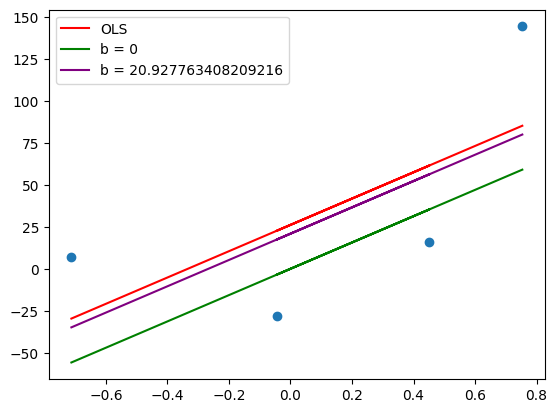

In [20]:
y_pred1 = ((78.35*x) + b).reshape(4)

plt.scatter(x,y)
plt.plot(x, lr.predict(x), color='red', label='OLS')
plt.plot(x, y_pred, color='green', label='b = 0')
plt.plot(x, y_pred1, color='purple',label='b = {}'.format(b))
plt.legend()
plt.show()


In [21]:
# Iteration 2:

loss_slope = -2* np.sum(y - m*x.ravel()-b)
loss_slope



np.float64(-41.85552681641843)

In [22]:
step_size = loss_slope*l_rate
step_size

np.float64(-4.185552681641844)

In [23]:
b = b-step_size
b

np.float64(25.11331608985106)

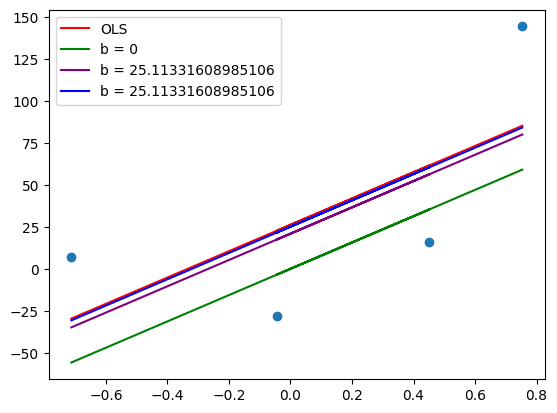

In [24]:
y_pred2 = ((78.35*x) + b).reshape(4)

plt.scatter(x,y)
plt.plot(x, lr.predict(x), color='red', label='OLS')
plt.plot(x, y_pred, color='green', label='b = 0')
plt.plot(x, y_pred1, color='purple',label='b = {}'.format(b))
plt.plot(x, y_pred2, color='blue',label='b = {}'.format(b))

plt.legend()
plt.show()

In [25]:
# Iteration 3:

loss_slope = -2* np.sum(y - m*x.ravel()-b)
loss_slope

np.float64(-8.371105363283675)

In [26]:
step_size = loss_slope*l_rate
step_size

np.float64(-0.8371105363283675)

In [27]:
b = b-step_size
b

np.float64(25.95042662617943)

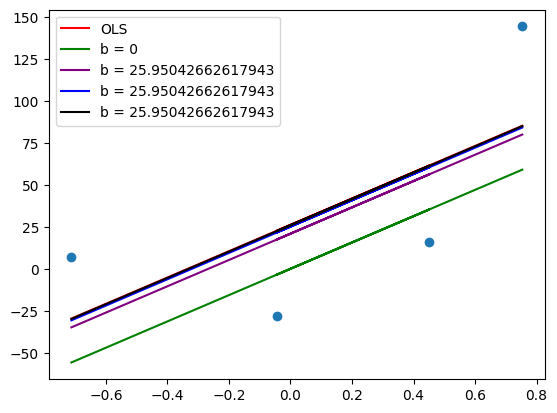

In [28]:
y_pred3 = ((78.35*x) + b).reshape(4)

plt.scatter(x,y)
plt.plot(x, lr.predict(x), color='red', label='OLS')
plt.plot(x, y_pred, color='green', label='b = 0')
plt.plot(x, y_pred1, color='purple',label='b = {}'.format(b))
plt.plot(x, y_pred2, color='blue',label='b = {}'.format(b))
plt.plot(x, y_pred3, color='black',label='b = {}'.format(b))


plt.legend()
plt.show()

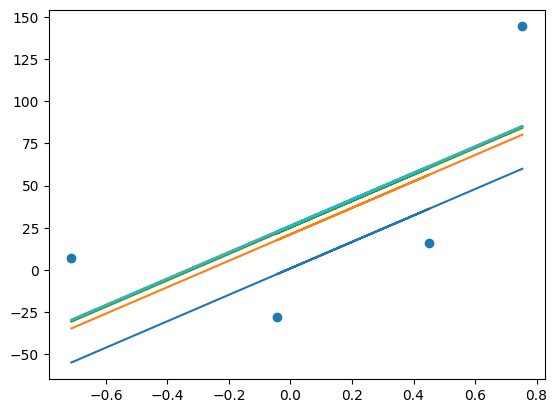

In [ ]:
# Now Doing this inside a loop
m = 78.35
b = -100
l_rate = 0.1
# try make lr to 0.01 and epochs to 100

epochs = 10

for i in range(epochs):
    loss_slope = -2*np.sum(y - m*x.ravel()-b)
    b = b-(l_rate*loss_slope)

    y_pred = m*x + b

    plt.plot(x, y_pred)

plt.scatter(x,y)
